# A–C · Complete development comparison

279 training cases; the same 42 development cases across majority, TF-IDF LR, linear SVM and frozen LEGAL-BERT LR, each with FULL and MASKED text. A retains team-reviewed status; B/C retain explicit provisional assumptions. No final-test evaluation. This notebook reads and independently verifies saved results; it does not refit models.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Image
RUN=Path('.')
read=lambda n:json.loads((RUN/n).read_text())
run=read('run.json')
display(pd.read_csv(RUN/'batch_class_counts.csv'))
display(pd.read_csv(RUN/'class_counts.csv').fillna(''))
display(run['assumptions'])

,batch,split,label_0,label_1,n
0,A,train,59,27,86
1,A,validation,8,8,16
2,B,train,64,33,97
3,B,validation,12,3,15
4,C,train,58,38,96
5,C,validation,5,6,11
6,ALL,train,181,98,279
7,ALL,validation,25,17,42


,scope,fold,n,label_0,label_1
0,train,,279,181,98
1,validation,,42,25,17
2,cv_training,1.0,185,120,65
3,cv_held_out,1.0,94,61,33
4,cv_training,2.0,186,121,65
5,cv_held_out,2.0,93,60,33
6,cv_training,3.0,187,121,66
7,cv_held_out,3.0,92,60,32


{'version': 'abc_provisional_assumptions_v1',
 'recorded_date': '2026-11-18',
 'scope': 'Prepare combined A-C data for provisional development experiments; do not run models yet.',
 'A': {'basis': 'Existing team-reviewed MVP package',
  'review_confirmation': 'experiments/mvp_a/team_review_confirmation.json',
  'promote_source_status': False},
 'B': {'basis': 'Prior explicit user assumption for Batch B',
  'user_instruction': 'Proceed, assuming the labels have been reviewed',
  'label_policy': 'Use the supplied draft_label_if_unanimous_include field for prepared development cases.',
  'source_status': 'pending_human_review',
  'promote_source_status': False},
 'C': {'basis': 'Explicit user authorization for a provisional run',
  'user_instruction': 'Record an explicit provisional-run assumption for batch C and combine all three datasets for A-C',
  'label_policy': 'Use a binary label only when all three saved reviewers agree for a case in the prepared C development package; stop on dis

## MASKED training-fold selection

The same three family-grouped folds are reused across all learned models. Select C by mean balanced accuracy, then macro F1, then smaller C. Selected settings are fixed across FULL/MASKED. Vocabulary/IDF, balanced class weights and the encoder classifier’s scaler are fitted within training pipelines only.

In [2]:
selection=read('selection.json')
display(pd.DataFrame([dict(model=m,C=t['C'],balanced_accuracy=t['balanced_accuracy'],macro_f1=t['macro_f1'],selected=t['C']==s['selected_C']) for m,s in selection.items() for t in s['grid']]))
display(run['models'])

,model,C,balanced_accuracy,macro_f1,selected
0,TFIDF_LR,0.1,0.623115,0.607339,False
1,TFIDF_LR,1.0,0.589274,0.589280,False
2,TFIDF_LR,10.0,0.627153,0.630102,True
3,TFIDF_SVM,0.1,0.584066,0.584587,False
4,TFIDF_SVM,1.0,0.629583,0.631814,False
5,TFIDF_SVM,10.0,0.632617,0.635995,True
6,LEGAL_BERT_LR,0.1,0.625956,0.613085,True
7,LEGAL_BERT_LR,1.0,0.608532,0.599458,False
8,LEGAL_BERT_LR,10.0,0.614298,0.606951,False


{'Majority': {'classifier': 'DummyClassifier',
  'strategy': 'most_frequent',
  'tie_label': 0},
 'TFIDF_LR': {'tfidfvectorizer': {'analyzer': 'word',
   'binary': False,
   'decode_error': 'strict',
   'dtype': 'float64',
   'encoding': 'utf-8',
   'input': 'content',
   'lowercase': True,
   'max_df': 1.0,
   'max_features': 30000,
   'min_df': 2,
   'ngram_range': [1, 2],
   'norm': 'l2',
   'preprocessor': None,
   'smooth_idf': True,
   'stop_words': None,
   'strip_accents': None,
   'sublinear_tf': False,
   'token_pattern': '(?u)\\b\\w\\w+\\b',
   'tokenizer': None,
   'use_idf': True,
   'vocabulary': None},
  'logisticregression': {'C': 10.0,
   'class_weight': 'balanced',
   'dual': False,
   'fit_intercept': True,
   'intercept_scaling': 1,
   'l1_ratio': None,
   'max_iter': 10000,
   'multi_class': 'deprecated',
   'n_jobs': None,
   'penalty': 'l2',
   'random_state': 20261023,
   'solver': 'liblinear',
   'tol': 0.0001,
   'verbose': 0,
   'warm_start': False}},
 'TFIDF

## Shared development metrics

Accuracy is overall correctness; balanced accuracy is mean recall across labels 0 and 1; macro F1 averages the two label F1 scores. Matrices use true rows and predicted columns in order 0 affirmed, 1 reversed/vacated. The figure shows raw counts and row percentages; exact normalized fractions are displayed below.

,model,variant,C,n,accuracy,balanced_accuracy,macro_f1,recall_0,recall_1
0,Majority,FULL,NaN,42,0.595238,0.500000,0.373134,1.00,0.000000
1,Majority,MASKED,NaN,42,0.595238,0.500000,0.373134,1.00,0.000000
2,TFIDF_LR,FULL,10.0,42,0.809524,0.821176,0.807780,0.76,0.882353
3,TFIDF_LR,MASKED,10.0,42,0.571429,0.536471,0.533333,0.72,0.352941
4,TFIDF_SVM,FULL,10.0,42,0.880952,0.881176,0.877551,0.88,0.882353
5,TFIDF_SVM,MASKED,10.0,42,0.547619,0.507059,0.499687,0.72,0.294118
6,LEGAL_BERT_LR,FULL,0.1,42,0.880952,0.881176,0.877551,0.88,0.882353
7,LEGAL_BERT_LR,MASKED,0.1,42,0.476190,0.503529,0.475000,0.36,0.647059


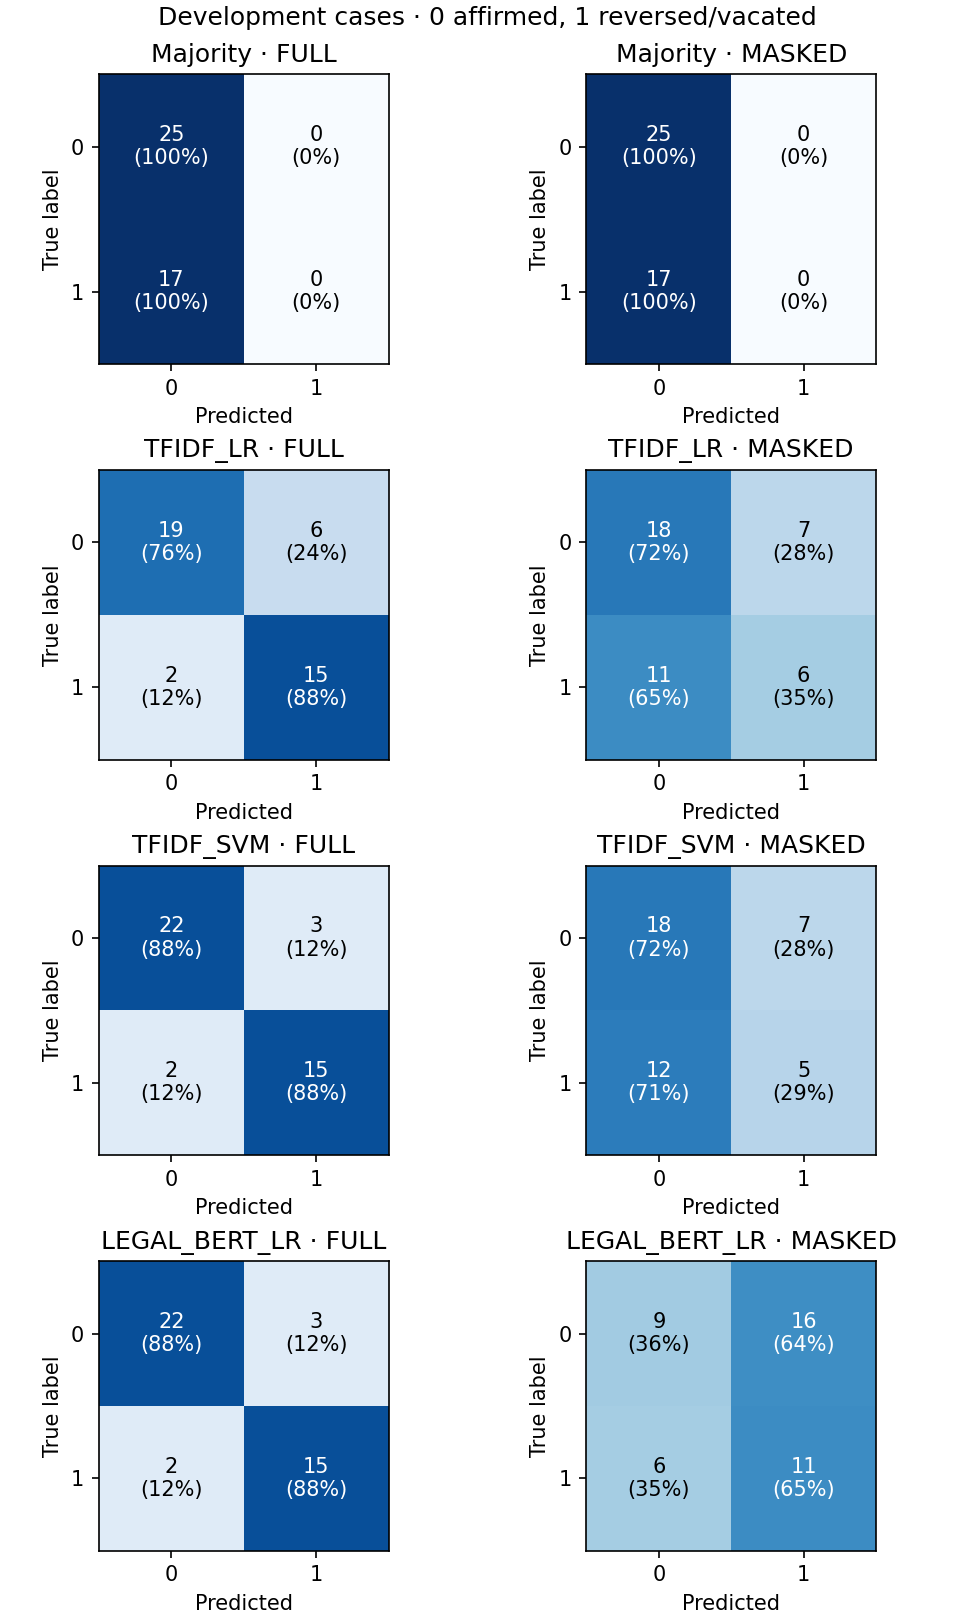

variant,FULL,MASKED,FULL minus MASKED
model,,,
LEGAL_BERT_LR,0.881176,0.503529,0.377647
Majority,0.500000,0.500000,0.000000
TFIDF_LR,0.821176,0.536471,0.284706
TFIDF_SVM,0.881176,0.507059,0.374118


Majority FULL


Predicted,0,1
True,,
0,1.0,0.0
1,1.0,0.0


Majority MASKED


Predicted,0,1
True,,
0,1.0,0.0
1,1.0,0.0


TFIDF_LR FULL


... (7 outputs left out)

LEGAL_BERT_LR FULL


Predicted,0,1
True,,
0,0.880000,0.120000
1,0.117647,0.882353


LEGAL_BERT_LR MASKED


Predicted,0,1
True,,
0,0.360000,0.640000
1,0.352941,0.647059


In [3]:
results=pd.read_csv(RUN/'results.csv')
display(results)
display(Image(filename=str(RUN/'confusion_matrices.png')))
paired=results.pivot(index='model',columns='variant',values='balanced_accuracy')
paired['FULL minus MASKED']=paired.FULL-paired.MASKED
display(paired)
for c in read('reporting_summary.json')['conditions']:
    print(c['model'],c['variant'])
    display(pd.DataFrame(c['row_normalized'],index=pd.Index([0,1],name='True'),columns=pd.Index([0,1],name='Predicted')))

## Frozen encoder and all-chunk coverage

Pinned LEGAL-BERT; up to 510 content tokens per chunk plus CLS/SEP, no overlap or truncation. Mean pooling excludes specials/padding and weights chunks by content-token count. All chunks contribute; encoder weights stay frozen. Cache-only reload matches the extracted vectors. Saved matrices contain 321 opinion vectors per variant, ordered by embedding_index.json.

In [4]:
display(run['encoder_settings'])
display(read('verification.json'))
display(read('length_summary.json'))
display(run['software'])

{'encoder': 'nlpaueb/legal-bert-base-uncased',
 'revision': '15b570cbf88259610b082a167dacc190124f60f6',
 'tokenizer': 'BertTokenizer',
 'use_fast': False,
 'content_tokens': 510,
 'overlap': 0,
 'padding_side': 'right',
 'batch_size_chunks': 4,
 'hidden_size': 768,
 'threads': 4,
 'pooling': 'last hidden layer; sum content-token vectors over all nonoverlapping chunks and divide by total content tokens; exclude special tokens and padding',
 'protocol_version': 1}

{'reference_reproduction': {'Majority': {'predictions_and_selection_identical': True,
   'max_decision_score_difference': 0},
  'TFIDF_LR': {'predictions_and_selection_identical': True,
   'max_decision_score_difference': 0.0},
  'TFIDF_SVM': {'predictions_and_selection_identical': True,
   'max_decision_score_difference': 0.0}},
 'saved_training_folds_reused': True,
 'family_disjoint_folds': True,
 'same_evaluation_cases_and_labels': True,
 'masked_only_selection': True,
 'fixed_selected_C_across_variants': True,
 'input_hashes_unchanged': True,
 'metrics_recomputed_from_predictions': True,
 'reserved_test_evaluated': False,
 'convergence_warnings': 0,
 'training_cases': 279,
 'evaluation_cases': 42,
 'conditions': 8,
 'encoder_frozen': True,
 'encoder_fine_tuned': False,
 'checkpoint_files_sha256': {'config.json': '716ea70c3c3e74bfe8496cc04cba7cd52f4ca45401e74042bb1058fe0390a1b6',
  'vocab.txt': '3aaa02f2e3a397eee0f813caa567c87cddab1045a4a6b8ac6261f0cc799efb8f',
  'pytorch_model.bin'

{'encoder': {'encoder': 'nlpaueb/legal-bert-base-uncased',
  'revision': '15b570cbf88259610b082a167dacc190124f60f6',
  'tokenizer': 'BertTokenizer',
  'use_fast': False,
  'content_tokens': 510,
  'overlap': 0,
  'padding_side': 'right',
  'batch_size_chunks': 4,
  'hidden_size': 768,
  'threads': 4,
  'pooling': 'last hidden layer; sum content-token vectors over all nonoverlapping chunks and divide by total content tokens; exclude special tokens and padding',
  'protocol_version': 1},
 'splits': {'train': {'cases': 279,
   'FULL': {'words': {'min': 107.0,
     'median': 465.0,
     'mean': 515.6057347670251,
     'p90': 830.6,
     'max': 2363.0},
    'tokens': {'min': 126.0,
     'median': 641.0,
     'mean': 706.5017921146954,
     'p90': 1117.2000000000007,
     'max': 2954.0},
    'chunks': {'min': 1.0,
     'median': 2.0,
     'mean': 1.8494623655913978,
     'p90': 3.0,
     'max': 6.0},
    'fraction_over_one_input': 0.6738351254480287,
    'total_chunks': 516},
   'MASKED': {'

{'numpy': '2.3.4',
 'scipy': '1.16.3',
 'scikit-learn': '1.7.2',
 'matplotlib': '3.10.7',
 'torch': '2.9.1',
 'transformers': '4.57.1',
 'tokenizers': '0.22.2',
 'huggingface-hub': '0.36.2',
 'pandas': '2.3.3',
 'nbformat': '5.10.4',
 'nbclient': '0.10.2',
 'ipykernel': '6.30.1'}

## Verify predictions, folds, metrics and embeddings

In [5]:
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score,confusion_matrix
pred=pd.read_csv(RUN/'predictions.csv')
splits=pd.read_csv(RUN/'splits.csv')
train=splits[splits.period=='train']
dev=splits[splits.period=='validation']
expected=dev.set_index('case_id')['label'].to_dict()
assert len(train)==279 and len(dev)==42 and len(results)==8 and len(pred)==336
assert set(train.family_id).isdisjoint(dev.family_id)
assert train.groupby('family_id').held_out_cv_fold.nunique().max()==1
assert (pred[pred.model=='Majority'].prediction==train.label.value_counts().idxmax()).all()
for _,r in results.iterrows():
    p=pred[(pred.model==r.model)&(pred.variant==r.variant)]
    assert len(p)==len(expected) and p.set_index('case_id')['label'].to_dict()==expected
    if r.model!='Majority':
        assert r.C==selection[r.model]['selected_C'] and (p.C==r.C).all()
    cm=confusion_matrix(p.label,p.prediction,labels=[0,1])
    metrics={'accuracy':accuracy_score(p.label,p.prediction),'balanced_accuracy':balanced_accuracy_score(p.label,p.prediction),'macro_f1':f1_score(p.label,p.prediction,labels=[0,1],average='macro'),'recall_0':cm[0,0]/cm[0].sum(),'recall_1':cm[1,1]/cm[1].sum()}
    for k,v in metrics.items():
        assert np.isclose(r[k],v,rtol=0,atol=1e-12)
    saved=next(c for c in read('reporting_summary.json')['conditions'] if c['model']==r.model and c['variant']==r.variant)
    assert saved['counts']==cm.tolist()
    assert np.allclose(saved['row_normalized'],cm/cm.sum(axis=1,keepdims=True))
for name,checksum in read('reporting_summary.json')['source_sha256'].items():
    assert hashlib.sha256((RUN/name).read_bytes()).hexdigest()==checksum
index=read('embedding_index.json')
assert [r['case_id'] for r in index['rows']]==splits.case_id.tolist()
for name,checksum in index['files_sha256'].items():
    assert hashlib.sha256((RUN/name).read_bytes()).hexdigest()==checksum
    vectors=np.load(RUN/name,allow_pickle=False)
    assert vectors.shape==(321,768) and np.isfinite(vectors).all()
print('Verified all 8 conditions, 336 predictions, identical evaluation IDs and both embedding matrices.')

Verified all 8 conditions, 336 predictions, identical evaluation IDs and both embedding matrices.


## Interpretation

These are provisional development estimates. A/B validation cases have been inspected before; masks differ by batch; family-companion uncertainties remain. A FULL/MASKED difference between separately fitted pipelines is not a same-model phrase-deletion effect. All failed predictions are preserved. Reproduction instructions are in REPORT.md; select the recorded environment’s Python kernel to rerun this notebook.